<a href="https://colab.research.google.com/github/nlquantumm-source/Random/blob/main/REF1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install finished. If an import fails below, use Runtime > Restart session, then run stage01_problem.py again.
CuPy GPU arrays: True | Aer device: GPU | quick mode: False | outputs -> /content/outputs
2.8-E01  x_f = P[x0, u, G_p; theta],  y = M[x_f, H_s, G_c; theta]
theta   : L1_0 FeNi (tetrataenite), Ms=1.27e+06 A/m, Ku=1.3e+06 J/m^3, A=1.5e-11 J/m, T_order=593.0 K
u(t)    : 650.0 K -> 530.0 K in 1.0 h, hold 100 h
A       : Br>=0.9 T, HcJ>=3e+05 A/m, (BH)max>=100 kJ/m^3, retention>=0.99 over 10.0 y at 423.0 K
2.8-E08 : require Pr(y in A) >= 1 - eps = 0.90


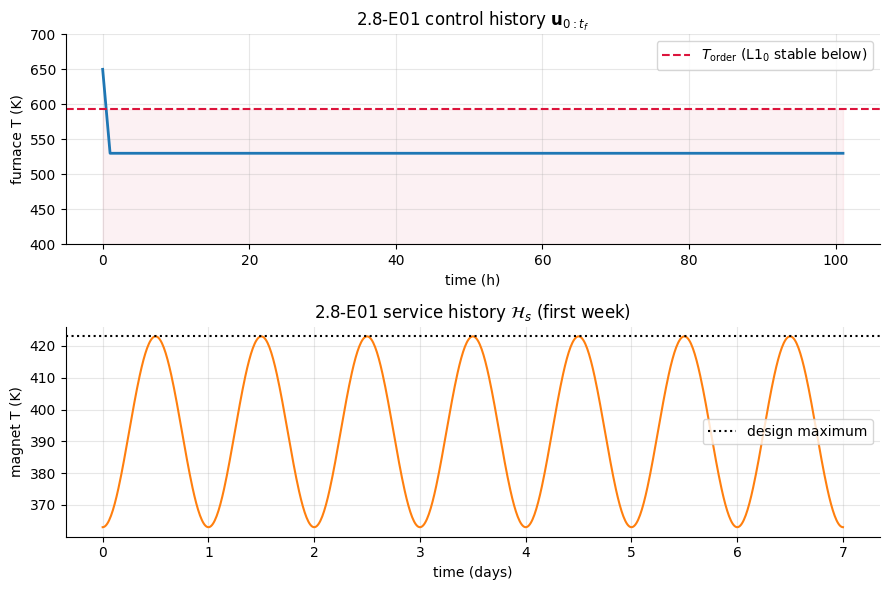

Stage 1 complete. Ready next: stage02_electronic_nuclear.py, stage04_phase_selection.py


In [1]:
# =============================================================================
# stage01_problem.py - STAGE 1: Define the problem
# Equations 2.8-E01, 2.8-E08
# =============================================================================

"""Stage 1: state the initial material, the controls and the acceptance region.

2.8-E01 writes the workflow as two maps,
``x_f = P[x0, u(0:tf), G_p; theta]`` and ``y = M[x_f, H_s, G_c; theta]``.
This cell fixes their inputs: ``MaterialParameters`` (theta),
``ProcessRecipe`` (u and G_p), and the service history H_s. It also fixes
the acceptance region A used in 2.8-E08, ``Pr(y in A | R, I) >= 1 - eps``.

Graph: the two inputs of E01 drawn on time axes. The top panel is the
furnace control history u(t). The bottom panel is the service temperature
history H_s(t). Requirements are drawn as shaded acceptable regions so the
target of E08 is visible from the start.

Every number below is a literature-scale placeholder for L1_0 FeNi.
Replace it with your measured or cited value before using a result in the
paper.
"""

# -----------------------------------------------------------------------------
# SETUP PART 1 of 2: install packages (same in every file)
# Install the quantum-chemistry, quantum-hardware and GPU simulation stack.
#
# Packages
# --------
# * ``qiskit`` 2.x and ``qiskit-aer-gpu`` -- circuits and GPU simulators.
# * ``qiskit-nature`` 0.8 with ``pyscf`` -- molecular and lattice
#   Hamiltonians (fermion-to-qubit mappings, UCCSD ansatz).
# * ``quantum-metal`` 0.9 (imports as ``qiskit_metal``) -- superconducting
#   qubit layout, rendered headless in Colab.
# * ``scqubits`` -- transmon spectra from the Metal design parameters.
# * ``cupy`` (preinstalled on Colab GPU runtimes) -- GPU arrays and FFTs for
#   the wavepacket, phase-field and micromagnetic solvers.
# -----------------------------------------------------------------------------
import importlib.util
import subprocess
import sys

CORE_PACKAGES = [
    "qiskit>=2.0,<3",
    "qiskit-nature==0.8.0",
    "pyscf>=2.6",
    "quantum-metal==0.9.0",
    "scqubits>=4.1",
]


def pip_install(packages):
    """Install ``packages`` quietly with the running interpreter's pip."""
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *packages], check=True
    )


def has_nvidia_gpu():
    """Return True when ``nvidia-smi`` lists at least one GPU."""
    try:
        out = subprocess.run(
            ["nvidia-smi", "-L"], capture_output=True, text=True, check=False
        )
    except FileNotFoundError:
        return False
    return "GPU" in out.stdout


def install_environment():
    """Install every package needed by Stages 1-10."""
    pip_install(CORE_PACKAGES)
    if has_nvidia_gpu():
        try:
            pip_install(["qiskit-aer-gpu==0.18.2"])
        except subprocess.CalledProcessError:
            print("GPU Aer wheel failed; falling back to CPU qiskit-aer.")
            pip_install(["qiskit-aer==0.18.2"])
        if importlib.util.find_spec("cupy") is None:
            pip_install(["cupy-cuda12x"])
    else:
        print("No NVIDIA GPU found: installing CPU qiskit-aer.")
        pip_install(["qiskit-aer==0.18.2"])


if importlib.util.find_spec("qiskit_nature") is None:
    install_environment()
    print(
        "Install finished. If an import fails below, use Runtime > "
        "Restart session, then run stage01_problem.py again."
    )
else:
    print("Packages already installed.")
# -----------------------------------------------------------------------------
# SETUP PART 2 of 2: shared imports, constants, helpers (same in every file)
# Shared utilities used by every stage of the workflow.
#
# The cell defines SI constants, picks the array backend (CuPy on the L4 GPU,
# NumPy otherwise), and provides helpers to save figures, render animations
# inline and record validity checks. Set the environment variable
# ``FENI_QUICK=1`` before running to shrink every grid for a fast smoke test.
# -----------------------------------------------------------------------------
import json
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import animation
from scipy import constants as sc

try:
    from IPython.display import HTML, display
except ImportError:  # plain Python fallback
    HTML = str
    display = print

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import cupy as cp

    cp.cuda.runtime.getDeviceCount()
    xp = cp
    GPU_AVAILABLE = True
except Exception:  # noqa: BLE001 - any CUDA/import failure -> CPU
    cp = None
    xp = np
    GPU_AVAILABLE = False

QUICK = os.environ.get("FENI_QUICK", "0") == "1"
SAVE_GIFS = os.environ.get("FENI_SAVE_GIFS", "1") == "1"
OUTPUT_DIR = (
    Path("/content/outputs")
    if Path("/content").exists()
    else (Path("outputs"))
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

matplotlib.rcParams["animation.embed_limit"] = 100.0
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# --- SI constants ------------------------------------------------------------
KB = sc.k
HBAR = sc.hbar
H_PLANCK = sc.h
MU0 = sc.mu_0
EV = sc.e
AMU = sc.atomic_mass
M_E = sc.m_e
C_LIGHT = sc.c
MU_B = sc.physical_constants["Bohr magneton"][0]
GAMMA_E = sc.physical_constants["electron gyromag. ratio"][0]  # s^-1 T^-1
HARTREE = sc.physical_constants["Hartree energy"][0]
BOHR = sc.physical_constants["Bohr radius"][0]
AU_TIME = sc.physical_constants["atomic unit of time"][0]
PHI0 = sc.physical_constants["mag. flux quantum"][0]
ANGSTROM = 1.0e-10
YEAR = 365.25 * 24 * 3600.0

# Keep results from earlier stages when this file runs in the same
# session (%run -i): create STATE only once.
if "STATE" not in globals():
    STATE = {"checks": []}


def to_numpy(array):
    """Return ``array`` as a NumPy array, copying from the GPU if needed."""
    if GPU_AVAILABLE and isinstance(array, cp.ndarray):
        return cp.asnumpy(array)
    return np.asarray(array)


def aer_device():
    """Return ``"GPU"`` when qiskit-aer was built with CUDA, else ``"CPU"``."""
    try:
        from qiskit_aer import AerSimulator
    except ImportError:
        return "CPU"
    return "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"


def save_figure(fig, name):
    """Save ``fig`` as PNG in ``OUTPUT_DIR`` and show it."""
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=140)
    plt.show()
    plt.close(fig)


def show_animation(fig, anim, name, fps=10):
    """Display ``anim`` inline (JS player) and optionally save it as GIF."""
    if SAVE_GIFS:
        anim.save(
            OUTPUT_DIR / f"{name}.gif", writer=animation.PillowWriter(fps=fps)
        )
    html = anim.to_jshtml(fps=fps)
    plt.close(fig)
    display(HTML(html))


def check(label, value, target, rtol=None, atol=None, upper=None):
    """Record and print a numerical validity test from the equation register.

    Parameters
    ----------
    label : str
        Equation ID and short description.
    value, target : float
        Computed and expected values.
    rtol, atol : float, optional
        Relative or absolute tolerance for ``|value - target|``.
    upper : float, optional
        If given, the test is ``value <= upper`` instead.
    """
    if upper is not None:
        passed = bool(value <= upper)
    else:
        tol = atol if atol is not None else rtol * max(abs(target), 1e-300)
        passed = bool(abs(value - target) <= tol)
    STATE["checks"].append(
        {
            "check": label,
            "value": float(value),
            "target": float(target),
            "passed": passed,
        }
    )
    flag = "PASS" if passed else "FAIL"
    print(f"[{flag}] {label}: value={value:.6g}, target={target:.6g}")
    return passed


def parse_si(text):
    """Convert a Metal-style quantity such as ``"10nH"`` to an SI float."""
    prefixes = {
        "f": 1e-15,
        "p": 1e-12,
        "n": 1e-9,
        "u": 1e-6,
        "m": 1e-3,
        "": 1.0,
        "k": 1e3,
        "M": 1e6,
        "G": 1e9,
    }
    match = re.fullmatch(
        r"\s*([-+0-9.eE]+)\s*([fpnumkMG]?)[A-Za-z]*\s*", str(text)
    )
    if match is None:
        raise ValueError(f"Cannot parse quantity {text!r}")
    return float(match.group(1)) * prefixes[match.group(2)]


def save_state(name="workflow_state.json"):
    """Write every scalar entry of ``STATE`` to JSON for the paper record."""

    def scalar(value):
        if isinstance(value, (int, float, str, bool)):
            return value
        if isinstance(value, np.generic):
            return value.item()
        return None

    record = {
        key: scalar(val)
        for key, val in STATE.items()
        if scalar(val) is not None
    }
    record["checks"] = STATE["checks"]
    path = OUTPUT_DIR / name
    path.write_text(json.dumps(record, indent=2))
    print(f"State written to {path}")


STAGE_FILES = {
    1: "stage01_problem.py",
    2: "stage02_electronic_nuclear.py",
    3: "stage03_magnetism.py",
    4: "stage04_phase_selection.py",
    5: "stage05_kinetics.py",
    6: "stage06_microstructure.py",
    7: "stage07_properties.py",
    8: "stage08_reversal.py",
    9: "stage09_performance.py",
    10: "stage10_decision.py",
}
STAGE_NEEDS = {
    1: [],
    2: [],
    3: [1, 2],
    4: [1],
    5: [4],
    6: [5],
    7: [6],
    8: [7],
    9: [8],
    10: [6, 9],
}
STATE.setdefault("done", [])


def require(*stages):
    """Stop with a clear message if a prerequisite stage has not run."""
    missing = [n for n in stages if n not in STATE["done"]]
    if missing:
        files = ", ".join(STAGE_FILES[n] for n in missing)
        raise RuntimeError(
            f"Run these first (with %run -i, in this session): {files}"
        )


def mark_done(stage):
    """Record that ``stage`` finished and list the stages now ready to run."""
    if stage not in STATE["done"]:
        STATE["done"].append(stage)
    ready = [
        STAGE_FILES[n]
        for n, needs in STAGE_NEEDS.items()
        if n not in STATE["done"] and all(m in STATE["done"] for m in needs)
    ]
    print(
        f"Stage {stage} complete. Ready next: "
        f"{', '.join(ready) if ready else 'none (workflow finished)'}"
    )


AER_DEVICE = aer_device()
print(
    f"CuPy GPU arrays: {GPU_AVAILABLE} | Aer device: {AER_DEVICE} | "
    f"quick mode: {QUICK} | outputs -> {OUTPUT_DIR.resolve()}"
)
if "T0_WALL" not in globals():
    T0_WALL = time.time()
# -----------------------------------------------------------------------------
# STAGE CODE STARTS HERE
# -----------------------------------------------------------------------------
require()

from dataclasses import asdict, dataclass


@dataclass
class MaterialParameters:
    """Intrinsic parameters theta for L1_0 FeNi (placeholders, SI units)."""

    name: str = "L1_0 FeNi (tetrataenite)"
    ms: float = 1.27e6  # A/m, saturation magnetization at 300 K
    ku_ordered: float = 1.3e6  # J/m^3, uniaxial anisotropy at eta = 1
    a_exchange: float = 1.5e-11  # J/m, exchange stiffness
    t_order: float = 593.0  # K, chemical order-disorder temperature
    t_curie: float = 830.0  # K
    lattice_a: float = 3.58e-10  # m, fcc-derived cubic cell edge
    spin_s: float = 1.0  # effective local spin for 2.6-E02
    callen_exponent: float = 3.0  # K(T)/K(300) = (Ms(T)/Ms(300))**n
    atomic_density: float = 9.1e28  # atoms/m^3
    e_vac_formation: float = 1.60  # eV
    e_vac_migration: float = 1.30  # eV
    attempt_frequency: float = 1.0e13  # Hz


@dataclass
class ProcessRecipe:
    """Controls u(t) and processing geometry G_p for one candidate recipe."""

    t_start: float = 650.0  # K, start above T_order (disordered)
    t_anneal: float = 530.0  # K, ordering anneal
    ramp_time: float = 3600.0  # s
    hold_time: float = 3.6e5  # s (100 h)
    half_thickness: float = 2.0e-3  # m, slab half-thickness
    thermal_diffusivity: float = 5.0e-6  # m^2/s
    vacancy_enhancement: float = 1.0e10  # e.g. irradiation (hypothesis)
    packing_fraction: float = 0.90  # phi in 2.7-E02
    ni_fraction: float = 0.48  # nominal Ni atomic fraction


@dataclass
class Requirements:
    """Acceptance region A and tolerated failure probability epsilon."""

    br_min: float = 0.90  # T
    hcj_min: float = 3.0e5  # A/m
    bhmax_min: float = 1.0e5  # J/m^3
    retention_min: float = 0.99  # fraction surviving the service life
    service_temperature: float = 423.0  # K (150 C)
    service_years: float = 10.0
    epsilon: float = 0.10

    def accepts(self, y):
        """Return a boolean (or array) marking outputs ``y`` that lie in A."""
        return np.logical_and.reduce(
            [
                np.asarray(y["br"]) >= self.br_min,
                np.asarray(y["hcj"]) >= self.hcj_min,
                np.asarray(y["bhmax"]) >= self.bhmax_min,
                np.asarray(y["retention"]) >= self.retention_min,
            ]
        )


def furnace_temperature(t, recipe):
    """Return the control history u(t): linear ramp then isothermal hold."""
    frac = np.clip(np.asarray(t, dtype=float) / recipe.ramp_time, 0.0, 1.0)
    return recipe.t_start + frac * (recipe.t_anneal - recipe.t_start)


def service_temperature(t, req, swing=60.0, period=YEAR / 365.25):
    """Return a daily-cycling service temperature history H_s(t)."""
    phase = 0.5 * (1.0 - np.cos(2.0 * np.pi * np.asarray(t) / period))
    return req.service_temperature - swing * (1.0 - phase)


MAT = MaterialParameters()
RECIPE = ProcessRecipe()
REQ = Requirements()
STATE.update({f"mat_{k}": v for k, v in asdict(MAT).items()})
STATE.update({f"recipe_{k}": v for k, v in asdict(RECIPE).items()})
STATE.update({f"req_{k}": v for k, v in asdict(REQ).items()})

print("2.8-E01  x_f = P[x0, u, G_p; theta],  y = M[x_f, H_s, G_c; theta]")
print(
    f"theta   : {MAT.name}, Ms={MAT.ms:.3g} A/m, Ku={MAT.ku_ordered:.3g} "
    f"J/m^3, A={MAT.a_exchange:.3g} J/m, T_order={MAT.t_order} K"
)
print(
    f"u(t)    : {RECIPE.t_start} K -> {RECIPE.t_anneal} K in "
    f"{RECIPE.ramp_time / 3600:.1f} h, hold {RECIPE.hold_time / 3600:.0f} h"
)
print(
    f"A       : Br>={REQ.br_min} T, HcJ>={REQ.hcj_min:.3g} A/m, "
    f"(BH)max>={REQ.bhmax_min / 1e3:.0f} kJ/m^3, "
    f"retention>={REQ.retention_min} over {REQ.service_years} y at "
    f"{REQ.service_temperature} K"
)
print(f"2.8-E08 : require Pr(y in A) >= 1 - eps = {1 - REQ.epsilon:.2f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 6))
t_proc = np.linspace(0, RECIPE.ramp_time + RECIPE.hold_time, 600)
axes[0].plot(t_proc / 3600, furnace_temperature(t_proc, RECIPE), lw=2)
axes[0].axhline(
    MAT.t_order,
    ls="--",
    c="crimson",
    label=r"$T_{\rm order}$ (L1$_0$ stable below)",
)
axes[0].fill_between(
    t_proc / 3600, 0, MAT.t_order, color="crimson", alpha=0.06
)
axes[0].set(
    xlabel="time (h)",
    ylabel="furnace T (K)",
    title=r"2.8-E01 control history $\mathbf{u}_{0:t_f}$",
    ylim=(400, 700),
)
axes[0].legend()
t_serv = np.linspace(0, 7 * 24 * 3600, 800)
axes[1].plot(t_serv / 86400, service_temperature(t_serv, REQ), c="tab:orange")
axes[1].axhline(REQ.service_temperature, ls=":", c="k", label="design maximum")
axes[1].set(
    xlabel="time (days)",
    ylabel="magnet T (K)",
    title=r"2.8-E01 service history $\mathcal{H}_s$ (first week)",
)
axes[1].legend()
save_figure(fig, "stage1_controls_and_service")

mark_done(1)
